<a href="https://colab.research.google.com/github/danaghafour/DD2434/blob/main/1E-BLR-HT26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1E.1: Bayesian linear regression (known noise)

This notebook accompanies Section 1.1 of Assignment 1E, 2026. Use NumPy and SciPy for the numerical implementation and Matplotlib for plots; do not use torch. The provided data-loading cell uses pandas to read the CSV file. Do not change the seeds. Include the code of every function you implement, together with the requested plots, tables and discussion, in your report.

**Submission.** Submit your completed notebooks and any supporting source files in two clearly labelled versions: one with comments and one without comments. Both versions must contain the same executable code and produce the same results. Remove only comments from the second version. We will use the version without comments during the oral exam, where you will explain your implementation. Include the commented code in the report appendix.

**Model.** For inputs $x_i\in\mathbb R$, use the design vector $\tilde x_i=(1,x_i)^\top$ (intercept and slope), weights $w=(w_0,w_1)^\top$, and
$$
y_i=\tilde x_i^\top w+\varepsilon_i,\qquad
\varepsilon_i\overset{\mathrm{iid}}\sim\mathcal N(0,\sigma^2),\qquad
w\sim\mathcal N(m_0,S_0),
$$
with known noise variance $\sigma^2$. As discussed in the Module 1 exercise session, Exercise 1.5, the posterior and posterior predictive distribution are
$$
p(w\mid X,y)=\mathcal N(w\mid m_N,S_N),\qquad
S_N=(S_0^{-1}+\sigma^{-2}X^\top X)^{-1},\qquad
m_N=S_N(S_0^{-1}m_0+\sigma^{-2}X^\top y),
$$
$$
p(y_\star\mid x_\star,X,y)=\mathcal N\!\left(y_\star\mid\tilde x_\star^\top m_N,
\sigma^2+\tilde x_\star^\top S_N\tilde x_\star\right).
$$
Here $X\in\mathbb R^{N\times2}$ contains the design vectors as rows. Plugging in the ML weights gives the predictive distribution $\mathcal N(\tilde x_\star^\top\hat w^{\rm ML},\sigma^2)$.

The **Provided code** section contains an implementation of data simulation and functions for the closed-form posterior, the ML estimate and the posterior predictive distribution. Use these functions without modifying them. Complete the functions marked with `NotImplementedError`; that exception is a placeholder for your implementation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, multivariate_normal
from scipy.special import logsumexp

SEED = 2026  # Do not change the seed
rng = np.random.default_rng(SEED)

## Provided code

In [2]:
def design_matrix(x):
    # Map inputs of shape [N] to the design matrix of shape [N, 2] with a bias column.
    x = np.atleast_1d(np.asarray(x, dtype=float))
    return np.column_stack([np.ones_like(x), x])


def simulate_data(N, noise_std, w_true, rng, x_low=-1.0, x_high=1.0):
    # Draw x ~ U(x_low, x_high) and y = X w_true + eps, eps ~ N(0, noise_std^2).
    x = rng.uniform(x_low, x_high, size=N)
    X = design_matrix(x)
    y = X @ w_true + rng.normal(0.0, noise_std, size=N)
    return X, y


def infer_posterior(X, y, prior_mean, prior_cov, noise_std):
    # Closed-form posterior N(w | m_N, S_N) for Bayesian linear regression with known noise.
    noise_var = noise_std**2
    prior_precision = np.linalg.inv(prior_cov)
    post_cov = np.linalg.inv(prior_precision + X.T @ X / noise_var)
    post_mean = post_cov @ (prior_precision @ prior_mean + X.T @ y / noise_var)
    return post_mean, post_cov


def ml_estimate(X, y):
    # Least-squares / maximum-likelihood weights.
    return np.linalg.lstsq(X, y, rcond=None)[0]


def predictive_posterior(X_new, post_mean, post_cov, noise_std):
    # Marginal posterior predictive mean and variance at each row of X_new.
    pred_mean = X_new @ post_mean
    pred_var = noise_std**2 + np.einsum("ij,jk,ik->i", X_new, post_cov, X_new)
    return pred_mean, pred_var

### Parameters and data (do not change)

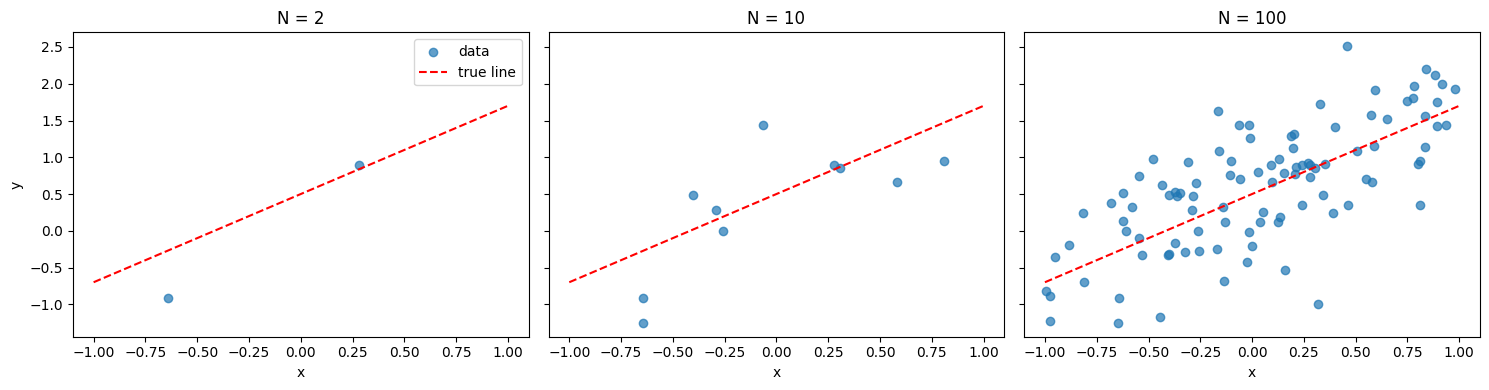

In [3]:
NOISE_STD = 0.5
PRIOR_MEAN = np.zeros(2)
PRIOR_COV = np.eye(2)
W_TRUE = np.array([0.5, 1.2])
Ns = [2, 10, 100]

# One dataset of 100 points; the N=2 and N=10 datasets are its first N points.
X_all, y_all = simulate_data(100, NOISE_STD, W_TRUE, rng)
datasets = {N: (X_all[:N], y_all[:N]) for N in Ns}

fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
x_line = np.linspace(-1, 1, 100)
for ax, N in zip(axs, Ns):
    X, y = datasets[N]
    ax.scatter(X[:, 1], y, alpha=0.7, label="data")
    ax.plot(x_line, design_matrix(x_line) @ W_TRUE, "r--", label="true line")
    ax.set_title(f"N = {N}")
    ax.set_xlabel("x")
axs[0].set_ylabel("y")
axs[0].legend()
plt.tight_layout()
plt.show()

### Question 1.1.1: Checking the posterior (2 points)

**(a)** Implement `grid_posterior`. Evaluate the unnormalised log posterior $\log p(y\mid X,w)+\log p(w)$ on the supplied grid of $(w_0,w_1)$ values, using only the likelihood and prior log-densities from `scipy.stats`, not the closed-form posterior. Normalise the density numerically on the grid. For $N=2,10,100$, overlay its contours with those of the closed-form posterior from `infer_posterior`, and report the maximum absolute difference between the two densities on the grid.

**(b)** Implement `sequential_posterior`. Process the observations one at a time, using the posterior after $n$ observations as the prior for observation $n+1$. Show that after all 100 observations the sequential and batch posteriors agree up to numerical precision by comparing their mean vectors and covariance matrices. Plot the posterior contours after $n=0,1,2,5,20,100$ observations with the true weights marked, and briefly discuss how the posterior changes.

In [5]:
def grid_posterior(w0_grid, w1_grid, X, y, prior_mean, prior_cov, noise_std):
    # Return a density array with shape (len(w0_grid), len(w1_grid)).
    W0, W1 = np.meshgrid(w0_grid, w1_grid, indexing="ij")
    weights = np.stack((W0, W1), axis=-1)  # Shape (n_w0, n_w1, 2).

    # Evaluate the prior and all observation likelihoods at candidate weights.
    # Do not use infer_posterior here: this is an independent numerical check.
    log_joint = multivariate_normal.logpdf(weights, mean=prior_mean, cov=prior_cov)
    for xi, yi in zip(X, y):
        predicted_y = xi[0] * W0 + xi[1] * W1
        log_joint += norm.logpdf(yi, loc=predicted_y, scale=noise_std)

    # A grid sums probability MASSES, whereas a pdf measures DENSITY.
    # To normalize the density, account for each cell's area delta_w0 * delta_w1.
    dw0 = w0_grid[1] - w0_grid[0]
    dw1 = w1_grid[1] - w1_grid[0]
    log_normalizer = logsumexp(log_joint) + np.log(dw0 * dw1)
    density = np.exp(log_joint - log_normalizer)
    return density

N=  2: max absolute density difference = 6.22967e-05; grid integral = 1.00000000
N= 10: max absolute density difference = 6.08402e-14; grid integral = 1.00000000
N=100: max absolute density difference = 2.28084e-12; grid integral = 1.00000000


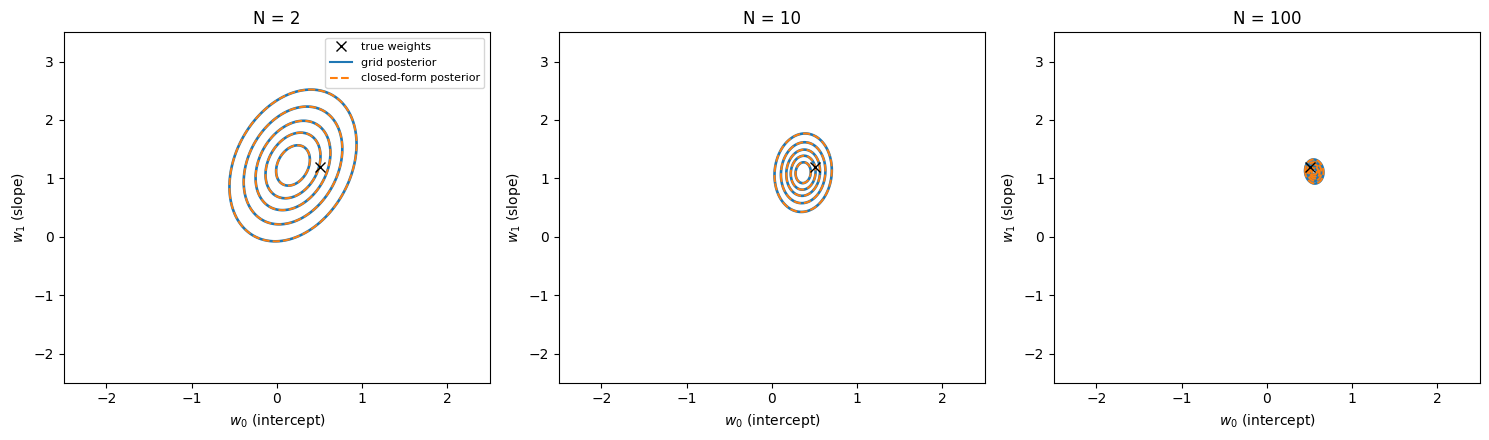

In [6]:
w0_grid = np.linspace(-2.5, 2.5, 401)
w1_grid = np.linspace(-2.5, 3.5, 401)
W0, W1 = np.meshgrid(w0_grid, w1_grid, indexing="ij")

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, N in zip(axs, Ns):
    X, y = datasets[N]
    # Compute the grid posterior and the closed-form posterior, overlay their contours
    # and print the maximum absolute difference between the two densities.
    grid_pdf = grid_posterior(w0_grid, w1_grid, X, y, PRIOR_MEAN, PRIOR_COV, NOISE_STD)
    post_mean, post_cov = infer_posterior(X, y, PRIOR_MEAN, PRIOR_COV, NOISE_STD)
    closed_pdf = multivariate_normal.pdf(
        np.stack((W0, W1), axis=-1), mean=post_mean, cov=post_cov
    )

    max_abs_diff = np.max(np.abs(grid_pdf - closed_pdf))
    integral = grid_pdf.sum() * (w0_grid[1] - w0_grid[0]) * (w1_grid[1] - w1_grid[0])
    print(f"N={N:3d}: max absolute density difference = {max_abs_diff:.6g}; "
          f"grid integral = {integral:.8f}")

    # Use identical density levels for the numerical and analytic contours.
    levels = np.array([0.10, 0.25, 0.45, 0.65, 0.85]) * min(grid_pdf.max(), closed_pdf.max())
    ax.contour(W0, W1, grid_pdf, levels=levels, colors="tab:blue", linewidths=1.9)
    ax.contour(W0, W1, closed_pdf, levels=levels, colors="tab:orange",
               linestyles="--", linewidths=1.4)
    ax.plot(*W_TRUE, "kx", markersize=7, label="true weights")
    ax.set(title=f"N = {N}", xlabel=r"$w_0$ (intercept)", ylabel=r"$w_1$ (slope)")
    # Proxy lines supply a reliable legend for Matplotlib contour collections.
    ax.plot([], [], color="tab:blue", label="grid posterior")
    ax.plot([], [], color="tab:orange", ls="--", label="closed-form posterior")
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
def sequential_posterior(X, y, prior_mean, prior_cov, noise_std):
    # Return means and covs, each of length N+1, including the prior at n=0.
    raise NotImplementedError("Implement sequential_posterior.")

In [ ]:
# Compare with the batch posterior and plot the posterior after n = 0, 1, 2, 5, 20, 100 points.

*Your discussion here.*

## Real data: Palmer penguins (Questions 1.1.2 and 1.1.3)

The file `data/penguins.csv` contains flipper length (input $x$) and body mass (output $y$) for 342 penguins of three species, collected at Palmer Station, Antarctica (Horst, Hill & Gorman, 2020; CC0 licence). Each observation is a pair of measurements from one penguin. Both variables are standardised to zero mean and unit variance. Use the prior $\mathcal N(0,I)$.

In the provided cell below, you can find code that estimates the noise standard deviation from the residuals of a least-squares fit to the full dataset. Keep this estimate, `PEN_NOISE_STD`, fixed in the subsequent real-data experiments. Section 1.2 instead asks you to infer an unknown noise precision.

The provided code defines the **training pool** using flipper lengths at or below the 70th-percentile cutoff; the remaining observations form the **extrapolation region**. Repeated flipper lengths mean that the split need not be exactly 70%/30%.

In [ ]:
import pandas as pd

# Provided code (do not change)
penguins = pd.read_csv("data/penguins.csv").dropna(subset=["flipper_length_mm", "body_mass_g"]).reset_index(drop=True)
flipper = penguins["flipper_length_mm"].to_numpy(dtype=float)
mass = penguins["body_mass_g"].to_numpy(dtype=float)
species = penguins["species"].to_numpy()

x_pen = (flipper - flipper.mean()) / flipper.std()
y_pen = (mass - mass.mean()) / mass.std()
X_pen = design_matrix(x_pen)

w_ols_all = ml_estimate(X_pen, y_pen)
PEN_NOISE_STD = np.std(y_pen - X_pen @ w_ols_all)       # treated as known from here on

x_split = np.quantile(x_pen, 0.7)
pool_idx = np.flatnonzero(x_pen <= x_split)             # training pool (shortest 70% of flippers)
extrap_idx = np.flatnonzero(x_pen > x_split)            # extrapolation region
print(f"{len(x_pen)} penguins, sigma (standardised units) = {PEN_NOISE_STD:.3f}")
for name, idx in [("training pool", pool_idx), ("extrapolation region", extrap_idx)]:
    sp, counts = np.unique(species[idx], return_counts=True)
    print(f"species in {name}: " + ", ".join(f"{s} {c}" for s, c in zip(sp, counts)))

rng_pen = np.random.default_rng(SEED + 10)  # Do not change the seed
pen_train = {N: rng_pen.choice(pool_idx, size=N, replace=False) for N in Ns}

fig, ax = plt.subplots(figsize=(6, 4.5))
for sp, marker in zip(["Adelie", "Chinstrap", "Gentoo"], ["o", "s", "^"]):
    m = species == sp
    ax.scatter(x_pen[m], y_pen[m], marker=marker, alpha=0.6, label=sp)
ax.axvline(x_split, color="k", ls=":", label="end of training pool")
ax.set_xlabel("flipper length (standardised)"); ax.set_ylabel("body mass (standardised)")
ax.legend()
plt.show()

### Question 1.1.2: Uncertainty and extrapolation on real data (2 points)

Implement `predictive_decomposition`, which returns the aleatoric variance $\sigma^2$ and the epistemic variance $\tilde x_\star^\top S_N\tilde x_\star$ at every supplied test input. For each training set of size $N=2,10,100$, use the posterior covariance fitted to that training set and evaluate the components on the plotting grid spanning the full observed range of flipper lengths.

Produce one panel for each $N$, showing:
- all 342 observations as a scatter plot of standardised flipper length against standardised body mass, with the $N$ training observations highlighted using a distinct colour or marker;
- the posterior predictive mean and its 95% predictive interval, using the total variance $\sigma^2+\tilde x_\star^\top S_N\tilde x_\star$;
- the pointwise 95% posterior credible interval for the noise-free regression mean,
  $$\tilde x_\star^\top m_N\ \pm\ 1.96\sqrt{\tilde x_\star^\top S_N\tilde x_\star};$$
- the ML prediction and its interval $\tilde x_\star^\top\hat w^{\rm ML}\pm1.96\sigma$.

The credible interval for the regression mean excludes observation noise. Compare the widths of all three intervals within the training-pool input range and in the extrapolation region, and explain how they change with $N$. For the Bayesian and ML predictive intervals, discuss how well they include the observed body masses in the extrapolation region.

In [ ]:
def predictive_decomposition(X_new, post_cov, noise_std):
    # Return aleatoric and epistemic variance arrays, each of length len(X_new).
    raise NotImplementedError("Implement predictive_decomposition.")

In [ ]:
x_star = np.linspace(x_pen.min() - 0.3, x_pen.max() + 0.3, 300)
X_star = design_matrix(x_star)
z = norm.ppf(0.975)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, N in zip(axs, Ns):
    idx = pen_train[N]
    X, y = X_pen[idx], y_pen[idx]
    # Insert your plotting code here
axs[0].set_ylabel("body mass (standardised)")
axs[0].legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

*Your discussion here.*

### Question 1.1.3: Calibration of predictive intervals on real data (3 points)

A 95% predictive interval is calibrated if it contains a new observation 95% of the time. Implement `coverage_real_data`. In each of $M$ repetitions:
1. draw $N$ training observations without replacement from `train_pool`;
2. draw one test observation from `test_pool`, excluding observations used for training;
3. record whether its body mass lies within the Bayesian 95% posterior predictive interval and within the ML interval $\tilde x_\star^\top\hat w^{\rm ML}\pm1.96\sigma$.

Use the prior $\mathcal N(0,I)$ for the Bayesian calculation and the fixed noise standard deviation `PEN_NOISE_STD` for both methods. Return the two empirical coverage fractions: the number of repetitions in which the interval contains the test observation, divided by $M$.

Run $M=3000$ repetitions for $N=2,10,100$ and two sampling designs:
- **random:** draw training and test observations from the full dataset;
- **extrapolation:** draw training observations from the training pool and test observations from the extrapolation region.

Convert the fractions to percentages when reporting your results. Use table columns **sampling design**, **N**, **Bayesian coverage (%)**, and **ML coverage (%)**. Explain when the Bayesian interval is approximately calibrated, when and why the ML interval fails, and why Bayesian coverage in the extrapolation design gets worse as $N$ increases.

In [ ]:
def coverage_real_data(x, y, N, M, train_pool, test_pool, prior_mean, prior_cov, noise_std, rng):
    # Return the Bayesian and ML empirical coverage fractions.
    raise NotImplementedError("Implement coverage_real_data.")

In [ ]:
M_real = 3000
rng_cov = np.random.default_rng(SEED + 1)  # Do not change the seed
all_idx = np.arange(len(x_pen))
designs = {"random": (all_idx, all_idx), "extrapolation": (pool_idx, extrap_idx)}
# Run both designs for N in {2, 10, 100} and print a table.

*Your table and discussion here.*

### Question 1.1.4: When the prior is wrong (3 points)

Return to simulated data, where the true weights are known. Implement `coverage_experiment`. In each of $M$ repetitions:
1. draw true weights $w\sim\mathcal N(w_{\rm mean},w_{\rm cov})$;
2. simulate $N$ training observations with $x\sim U(-1,1)$ and $\sigma=0.5$;
3. draw one new observation $y_\star=\tilde x_\star^\top w+\varepsilon_\star$ at the fixed test input $x_\star$;
4. record whether it lies within the Bayesian 95% predictive interval, using the supplied prior, and within the ML interval.

Return the two empirical coverage fractions, as in Question 1.1.3. Set $M=5000$, $x_\star=3$, and draw the true weights from $\mathcal N((2,2)^\top,I)$. Fit the Bayesian model with prior $\mathcal N(0,s_0^2I)$ for $s_0^2=0.1,1,10$ and $N=2,10,100$. Report the empirical coverages as percentages in a table, together with the ML coverage, which does not depend on the prior.

Discuss how prior confidence and the mismatch in the prior mean interact with $N$. When is the Bayesian predictive interval worse calibrated than the ML interval, and why? Why does the prior's influence disappear as $N$ increases, while the model misspecification in Question 1.1.3 remains?

*Optional, ungraded:* for one dataset with $N=10$ and $w=(2,2)^\top$, plot
$$\log p(y\mid X,s_0^2)=\log\mathcal N(y\mid Xm_0,\sigma^2I+s_0^2XX^\top)$$
as a function of $s_0^2$. Which value maximises it? This is the log model evidence for the regression problem. In Section 1.2, the ELBO provides a lower bound on the analogous log evidence for the Normal-Gamma model.

In [ ]:
def coverage_experiment(N, x_star, M, prior_mean, prior_cov, noise_std, rng, w_mean, w_cov):
    # Return the Bayesian and ML empirical coverage fractions.
    raise NotImplementedError("Implement coverage_experiment.")

In [ ]:
M = 5000
TRUE_W_MEAN = np.array([2.0, 2.0])
TRUE_W_COV = np.eye(2)
s0_sq_values = [0.1, 1.0, 10.0]
rng_mis = np.random.default_rng(SEED + 2)  # Do not change the seed
# Run the experiment and print a table with one row per s0^2 (Bayes) and one row for ML.

*Your table and discussion here.*

In [ ]:
# Optional (not graded)
# Insert your code here